# JIT 编译器 ― Numba

CFFI 与 Cython 都是用 C 编译器把 C 的程序做成扩展模块，再由 Python 调用；Numba 则用 LLVM 把 Python 的函数直接变成机器码。几乎不用操心编译这件事：只要加上 `@jit`，函数被调用时就会按参数的类型生成快速的代码。

如果只写 `@jit`，函数里仍然可以用 Python 的对象，有时反而变慢；因此要么加 `nopython=True`，要么一开始就用禁止 Python 对象的 `@njit`。编译器一旦发现需要 Python 对象，就会在编译时抛异常；类型确定下来之后，才能生成不使用 Python 对象的机器码。

- 类型与函数签名
- 数组、结构体、容器的类型
- NumPy 的数组运算与迭代
- 用 `vectorize` 做 ufunc
- 用 `stencil` 写核函数

In [1]:
import helper.matplotlib
import helper.magics
import numba as nb
from numba import jit, njit, cfunc
from numba.types import double, int32, float32, float64, int64, uint8
from numba import types as T
import numpy as np

## 数据类型

Numba 要生成机器码，就得知道计算中出现的变量是什么类型：它支持 C 的数值类型、指针类型、NumPy 的数组类型与结构体类型。

### 函数签名

函数参数的类型叫函数签名，可以写在 `@jit` 的第 1 个参数里；不写的话，就由第一次调用时的参数类型决定。

下面 `dummy_func()` 有 3 个参数，用不同类型的参数调用两次就会编译两次，看 `signatures` 就有两个签名：第 1 个对应 Python 的 `int`、`float`、`str`，也就是 `int64`、`float64`、`unicode_type`；第 2 个是 NumPy 的标量，类型与 `dtype` 相同，而数组则写成 `array()`。

In [2]:
import numpy as np
from numba import jit


@njit
def dummy_func(x, y, z):
    return (x, y, z)


dummy_func(1, 2.0, "hello")
dummy_func(np.float32(10), np.uint8(1), np.zeros(10))
dummy_func.signatures

[(int64, float64, unicode_type),
 (float32, uint8, Array(float64, 1, 'C', False, aligned=True))]

自己写签名时，先读入类型对象再拼起来：类型放在 `numba.core.types` 里，常用的可以直接从 `numba` 读；把类型对象用 `()` 调用，就得到返回那个类型的签名。下面的例子返回 `float64`，参数是 `float64` 与 `int32`。

In [3]:
from numba import float64, int32, int16

float64(float64, int32)

(float64, int32) -> float64

签名也可以用字符串写：下面 `dummy_func()` 有两个签名，第 2 个是用字符串写的。

In [4]:
@njit([float64(float64, int32), "float32(float32, int16)"])
def dummy_func(arr, n):
    return 0


dummy_func.signatures

[(float64, int32), (float32, int16)]

用 `typeof()` 可以知道 Python 的对象对应什么类型：`int` 是 `int64`、`float` 是 `float64`、复数是 `complex128`；`str` 是 `unicode_type`，`bytes` 则是只读的字节数组。

元组有两种：元素的类型全相同时是 `UniTuple`，类型由元素的类型与长度决定，相当于固定长度的数组；类型不同时是 `Tuple`，相当于没有名字的结构体。

In [5]:
import numba as nb

values = [
    1,
    2.0,
    1j,
    "hello",
    b"bindata",
    np.float32(10),
    np.zeros(3),
    (1, 2, 3),
    (1, 2.0),
]
for v in values:
    print(f"typeof( {repr(v):19s} ) : {nb.typeof(v)}")

typeof( 1                   ) : int64
typeof( 2.0                 ) : float64
typeof( 1j                  ) : complex128
typeof( 'hello'             ) : unicode_type
typeof( b'bindata'          ) : readonly bytes(uint8, 1d, C)
typeof( np.float32(10.0)    ) : float32
typeof( array([0., 0., 0.]) ) : array(float64, 1d, C)
typeof( (1, 2, 3)           ) : UniTuple(int64 x 3)
typeof( (1, 2.0)            ) : Tuple(int64, float64)


### 数组类型

在类型对象后面加 `[]` 就是那种元素的数组类型，写法与 Cython 相同，用 `:` 或 `::1` 排列：个数是维数，`::1` 表示那一维是连续的。

下面的代码是元素类型与排列都不同的 3 个二维数组类型，显示成 `array(元素类型, 维数, 排列)`，其中排列 `C` 是 C 的顺序、`F` 是 Fortran 的顺序、`A` 是未指定。用连续的类型，元素访问更快。

In [6]:
from numba.types import int32, float32, float64

%C int32[::1, :]; float32[:, :]; double[:, ::1]

              int32[::1, :]                               float32[:, :]                                double[:, ::1]              
-----------------------------------------  -------------------------------------------  -------------------------------------------
Array(int32, 2, 'F', False, aligned=True)  Array(float32, 2, 'A', False, aligned=True)  Array(float64, 2, 'C', False, aligned=True)


用 `Array()` 也能做数组类型，下面是 C 顺序的三维数组。

In [7]:
from numba.types import Array

Array(float32, 3, "C")

Array(float32, 3, 'C', False, aligned=True)

NumPy 的数组带着维数、形状、元素间隔等信息，而 C 里通常用指针与长度传数组。Numba 里用 `CPointer` 做指针类型。

下面的例子是加了 `@cfunc` 的 `sum1d()`：它变成 C 的调用形式，第 1 个参数是 `double` 数组开头的指针、第 2 个参数是元素的个数。`@cfunc` 的函数用来在扩展模块里当回调，从 Python 则通过 `ctypes` 属性取到 ctypes 的函数来调用，传 NumPy 数组时要转换成开头的指针。

In [8]:
from numba.types import CPointer


@cfunc(float64(CPointer(float64), int64))
def sum1d(xs, n):
    s = 0.0
    for i in range(n):
        s += xs[i]
    return s


print(sum1d.ctypes)
from ctypes import POINTER, c_double

arr = np.arange(0.0, 11.0)
sum1d.ctypes(arr.ctypes.data_as(POINTER(c_double)), len(arr))

55.0

### 结构体类型

Python 里没有对应的对象，但用 `Record.make_c_struct()` 可以定义结构体类型，参数是字段名与类型的排列；现在只能用标量类型与 `NestedArray` 的固定长度数组。

下面 `Triangle` 的 `xs` 与 `ys` 是形状 `(3,)` 的 `float64` 数组。

In [9]:
from numba.types import Record, NestedArray

Point = Record.make_c_struct(
    [
        ("id", int32),
        ("x", float64),
        ("y", float64),
    ]
)

Triangle = Record.make_c_struct(
    [
        ("id", int32),
        ("xs", NestedArray(float64, (3,))),
        ("ys", NestedArray(float64, (3,))),
    ]
)

`Record` 与 NumPy 的 `dtype` 可以互相转换：用 `Record.dtype` 取到 `dtype`，用 `numpy_support.from_dtype()` 从 `dtype` 做出 `Record`。

下面的例子做出 `dtype` 的 `Line_dtype`，再变成 `Record`，其中 `x` 与 `y` 是 `Point` 结构体。元素是结构体的 `NestedArray`，Numba 还不支持。

In [10]:
from numba.np import numpy_support

Line_dtype = np.dtype([("id", np.int32), ("start", Point.dtype), ("end", Point.dtype)])
Line = numpy_support.from_dtype(Line_dtype)

做出 `Line.dtype` 的结构体数组，再用 `.view(np.recarray)` 变成 `recarray`：用法相同，但 `recarray` 可以用属性读字段。

`length()` 计算每条线段的长度：结构体数组也好、`recarray` 也好，在编译过的函数里都能用属性名读字段。

In [11]:
@njit
def length(lines):
    x1 = lines.start.x
    x2 = lines.end.x
    y1 = lines.start.y
    y2 = lines.end.y
    return np.hypot(x2 - x1, y2 - y1)


lines = np.zeros(3, dtype=Line.dtype).view(np.recarray)

lines.start.x = [1, 2, 3]
lines.end.x = [10, 10, 10]
lines.start.y = [2, 2, 2]
lines.end.y = [8, 7, 6]

length(lines), length.py_func(lines)

(array([10.81665383,  9.43398113,  8.06225775]),
 array([10.81665383,  9.43398113,  8.06225775]))

### 把函数当参数

编译过的函数里，可以调用别的编译过的函数，也可以调用用 CFFI 读入的外部函数；函数还能当参数传进去。

下面例子里的 `func()` 是编译过的函数，`lib.sin()` 是用 CFFI 读入的 C 函数；把这两个传给 `sum_of_func()`，再把数组各元素的计算结果加起来。

In [12]:
from cffi import FFI


@njit
def func(x):
    return x * np.sin(x**2)


@njit
def sum_of_func(func, xs):
    s = 0.0
    for x in xs:
        s += func(x)
    return s


ffi = FFI()
ffi.cdef("double sin(double);")
lib = ffi.dlopen("msvcrt")

xs = np.linspace(0, 1, 1000)
print(sum_of_func(lib.sin, xs), sum_of_func(func, xs))

459.6586935836439 230.0398940446059


看 `sum_of_func()` 的签名：外部函数与编译过的函数调用方式不同，因此有两个签名。

In [13]:
for sig in sum_of_func.signatures:
    print(sig)

(ExternalFunctionPointer((float64,) -> float64), Array(float64, 1, 'C', False, aligned=True))
(type(CPUDispatcher(<function func at 0x000001F55BBDB950>)), Array(float64, 1, 'C', False, aligned=True))


编译过的函数实际上是 `CPUDispatcher` 对象，因为不同的参数类型对应不同的机器码：它对每个签名各持有一份机器码。调用时挑与类型相合的那份，这叫函数的重载。

`overloads` 属性里用 `OrderedDict` 放着签名与机器码的对应关系，用 `get_overload()` 可以取出某个签名对应的函数。

In [14]:
print(type(sum_of_func))
sum_of_func0 = sum_of_func.get_overload(sum_of_func.signatures[0])
sum_of_func0(lib.sin, xs)

<class 'numba.core.registry.CPUDispatcher'>


459.6586935836439

### 局域变量的类型

编译过的函数里，局域变量的类型由参数的类型与用法推出来，用 `inspect_types()` 能看到 Numba 的中间代码。

Numba 先把 Python 的函数变成 Numba 的中间代码，再变成 LLVM 的中间代码，最后由 LLVM 生成机器码；看中间代码就能明白类型是怎么推出来的。

下面的程序把 `float32` 传给 `dummy_func()`，再看中间代码。

In [15]:
@njit
def inc(x):
    x += 1.0
    return x


inc(np.float32(0.0))
inc.inspect_types()

inc (float32,)
--------------------------------------------------------------------------------
# File: C:\Users\ruoyu\AppData\Local\Temp\ipykernel_5112\914538076.py
# --- LINE 1 --- 
# label 0
#   x = arg(0, name=x)  :: float32

@njit

# --- LINE 2 --- 

def inc(x):

    # --- LINE 3 --- 
    #   $const6.1.0 = const(float, 1.0)  :: float64
    #   x.1 = inplace_binop(fn=<built-in function iadd>, immutable_fn=<built-in function add>, lhs=x, rhs=$const6.1.0, static_lhs=Undefined, static_rhs=Undefined)  :: float64
    #   del x
    #   del $const6.1.0

    x += 1.0

    # --- LINE 4 --- 
    #   $24return_value.4 = cast(value=x.1)  :: float64
    #   del x.1
    #   return $24return_value.4

    return x




从输出可以看出，`inc()` 的参数是 `float32`，但它要与 `float64` 的常量 `1.0` 一起计算，为了保住精度，返回值因此变成了 `float64`。

`x += 1.0` 的结果与 C 完全不同，这一点也值得注意：相加的结果没有放回 `x`，而是放进了新的变量 `x.1`。LLVM 里变量只能赋值一次，结果因此要放进新变量；为了不掉精度，类型也就变成 `float64` 了。

用本书的 `get_local_variables()` 能方便地看局域变量的类型：第 1 个参数是函数、第 2 个参数是签名的编号，返回以变量名为键、类型为值的字典。

In [16]:
from helper.numba import get_local_variables

get_local_variables(inc, 0)

{'arg.x': float32,
 'x': float32,
 'x.1': float64,
 '$24return_value.4': float64,
 '$const6.1.0': float64}

在编译过的函数里，可以用 Numba 的类型或 NumPy 的标量类型做类型转换：下面的代码先把常量 `1.0` 变成 `float32` 再相加，因为两边都是 `float32`，返回值也是 `float32`。

In [17]:
@njit
def inc(x):
    x += float32(1.0)
    return x


inc(np.float32(0.0))
get_local_variables(inc, 0)

{'arg.x': float32,
 'x': float32,
 'x.1': float32,
 '$18call.4': float32,
 '$42return_value.7': float32,
 '$6load_global.1': class(float32),
 '$const16.3.0': float64}

下面 `checksum()` 计算一字节无符号整数数组的校验和：用 C 写会返回一字节的整数，而 Numba 返回的是合计数，因为 `uint8` 之间相加会超出范围，Numba 就用 `uint64` 来保存合计数。

In [18]:
@njit
def checksum(xs):
    s = uint8(0)
    for x in xs:
        s += uint8(x)
    return s


arr = np.arange(200).astype(np.uint8)
checksum(arr)

19900

这是 `checksum()` 的局域变量的类型：`s` 一开始是 `uint8`，相加之后就变成 `uint64`。

In [19]:
get_local_variables(checksum, 0)

{'arg.xs': Array(uint8, 1, 'C', False, aligned=True),
 's': uint8,
 's.1': uint64,
 's.2': uint64,
 'x': uint8,
 'xs': Array(uint8, 1, 'C', False, aligned=True),
 '$28get_iter.5': iter(array(uint8, 1d, C)),
 '$30for_iter.1': pair<uint8, bool>,
 '$30for_iter.2': uint8,
 '$30for_iter.3': bool,
 '$38load_global.3': class(uint8),
 '$4load_global.0': class(uint8),
 '$50call.6': uint8,
 '$82return_value.3': uint64,
 '$binop_iadd58.7': uint64,
 '$const14.2.0': Literal[int](0),
 '$phi30.0': iter(array(uint8, 1d, C)),
 '$phi34.1': uint8}

要得到正确的校验和，就把相加的结果变回 `uint8`。

In [20]:
@njit
def checksum2(xs):
    s = uint8(0)
    for x in xs:
        s = uint8(s + x)
    return s


checksum2(arr)

188

再看局域变量的类型，`s` 的各次复制全都是 `uint8`。

In [21]:
get_local_variables(checksum2, 0)

{'arg.xs': Array(uint8, 1, 'C', False, aligned=True),
 's': uint8,
 's.1': uint8,
 's.2': uint8,
 'x': uint8,
 'xs': Array(uint8, 1, 'C', False, aligned=True),
 '$28get_iter.5': iter(array(uint8, 1d, C)),
 '$30for_iter.1': pair<uint8, bool>,
 '$30for_iter.2': uint8,
 '$30for_iter.3': bool,
 '$36load_global.2': class(uint8),
 '$4load_global.0': class(uint8),
 '$80return_value.3': uint8,
 '$binop_add48.6': uint64,
 '$const14.2.0': Literal[int](0),
 '$phi30.0': iter(array(uint8, 1d, C)),
 '$phi34.1': uint8}

### 容器类型

Python 的列表与字典什么类型都能放，用起来方便，但大量处理同一类型的数据时就慢了。Numba 里有带类型的 `List` 与 `Dict`：元素大小一致，能放在连续的内存里，访问也就更快。

下面 `filter_between()` 从 `arr` 里挑出位于 `vmin` 与 `vmax` 之间的值，因为不知道会挑出几个，就一个个加到 `List` 里。

In [22]:
from numba.typed import List


@njit
def filter_between(arr, vmin, vmax):
    r = List()
    for v in arr:
        if vmin < v < vmax:
            r.append(v)
    return r

比较 `filter_between()` 与 Python 的列表推导式的速度：数组的迭代慢，因此先转成列表再用推导式计算。

In [23]:
values = np.random.randn(100000)
lvalues = values.tolist()
r1 = filter_between(values, 0.1, 0.11)
%timeit filter_between(values, 0.1, 0.11)
%timeit [x for x in lvalues if 0.1 < x < 0.11]

718 μs ± 22 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


4.99 ms ± 143 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


在 Python 里，`List` 也可以当普通列表来用。

In [24]:
print(type(r1), len(r1), sum(r1))

<class 'numba.typed.typedlist.List'> 435 45.68481165176453


用 `_numba_type_` 能知道它在 Numba 里的类型：`r1` 的元素是 `float64`。

In [25]:
r1._numba_type_

ListType(float64)

下面 `group_mean()` 用字典的 `Dict` 分组，再计算平均值。

❶ 与 `List` 不同，在编译过的函数里 `{}` 会做出 `Dict`；为了让 Numba 正确推断键与值的类型，用 `group[0]` 与 `(0, 0.0)` 来初始化，其中键是组、值是“个数与合计”的元组。

❷ 用 `get()` 取出组的值，没有就返回初始值。❸ 更新个数与合计，最后从字典算出平均值。

In [26]:
from numba.typed import Dict
from numba.types import int64, float64, Tuple


@njit
def group_mean(group, arr):
    d = {group[0]: (0, 0.0)}  #❶
    for g, v in zip(group, arr):
        n, s = d.get(g, (0, 0.0))  #❷
        d[g] = n + 1, s + v  #❸

    r = {}
    for key, val in d.items():
        r[key] = val[1] / val[0]
    return r

比较 `group_mean()` 的编译版、原来的 Python 版与 Pandas 的 `groupby().mean()` 的速度：编译版接近 Pandas，而 Pandas 内部计算组的平均也是用 Cython 写的函数。Pandas 的函数覆盖不到的计算，就可以照这个例子的做法提速。

In [27]:
import pandas as pd

values = np.random.randn(100000)
group = np.random.randint(0, 100, size=len(values), dtype=np.int16)
grp_means = group_mean(group, values)
lvalues = values.tolist()
lgroup = group.tolist()
%timeit group_mean(group, values)
%timeit group_mean.py_func(lgroup, lvalues)
%timeit pd.Series(values).groupby(group).mean()

6.69 ms ± 1.13 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


19.1 ms ± 149 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


2.42 ms ± 54.1 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


在 Python 里，`Dict` 也可以当普通字典来用，确认 `grp_means` 的类型。

In [28]:
print(type(grp_means), grp_means._numba_type_)

<class 'numba.typed.typeddict.Dict'> DictType[int16,float64]<iv=None>


用 `items()` 取出键与值的排列，再用 `sorted()` 按键排序。

In [29]:
sorted(grp_means.items())[:4]

C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\typed\typeddict.py:39: NumbaTypeSafetyWarning: unsafe cast from int64 to int16. Precision may be lost.
  return d[key]


[(0, 0.02448172119183899),
 (1, -0.03719826704560102),
 (2, 0.028411674271242426),
 (3, 0.060215546319046485)]

## NumPy 的数组运算

Numba 认识数组的类型与 NumPy 的绝大多数函数，因此能生成快速的代码；还能用 `@vectorize` 做 ufunc、用 `@stencil` 写处理整个数组的核函数。

### 广播的优化

NumPy 计算数组的表达式时会做很多存放中间结果的临时数组，数组一大。这些申请与释放就影响速度；Numba 把数组的表达式转换成循环，因此不做中间数组。

In [30]:
@njit
def f1(x, y):
    return np.sin(x**2) + np.cos(y**2)


@njit
def f2(x, y):
    a = np.sin(x**2)
    b = np.cos(y**2)
    return a + b

Numba 也能处理广播，但把整个表达式合成一个 ufunc，有时反而更慢。

下面的例子里 `x` 是 `(1000, 1)`、`y` 是 `(1, 1000)`：用 NumPy 算 `sin(x**2) + cos(y**2)` 时，`sin()` 与 `cos()` 各算 1000 次，只有最后的加法被广播；而 `f1()` 把整个表达式做成一个 ufunc，于是 `sin()` 与 `cos()` 各算 100 万次。

NumPy 与把中间结果存进数组的 `f2()` 一样快，而把整个表达式合成一个的 `f1()` 慢得多；因此要按数组的形状来挑写法。

In [31]:
x, y = np.ogrid[-1:1:1000j, -1:1:1000j]
f1(x, y)
f2(x, y)
%timeit f1(x, y)
%timeit f2(x, y)
%timeit f1.py_func(x, y)

11.5 ms ± 492 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


2.7 ms ± 67.3 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


3.6 ms ± 157 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


用本书的 `display_func_code()` 能看到 Numba 内部用到的函数的代码，下面的例子是 `np.nanmean()` 的代码。

In [32]:
from helper.numba import display_func_code


@nb.njit
def f(x):
    return np.nanmean(x)


x = np.random.randn(10)
f(x)
display_func_code(f, np.nanmean)

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\np\arraymath.py: 1787
@overload(np.nanmean)
def np_nanmean(a):
    if not isinstance(a, types.Array):
        return
    isnan = get_isnan(a.dtype)

    def nanmean_impl(a):
        c = 0.0
        count = 0
        for view in np.nditer(a):
            v = view.item()
            if not isnan(v):
                c += v.item()
                count += 1
        # np.divide() doesn't raise ZeroDivisionError
        return np.divide(c, count)

    return nanmean_impl

```

也能看到与 Python 运算符对应的代码：下面的例子是加法，可以看出整数、浮点数、字符串各自用了不同的函数。

In [33]:
import operator


@nb.njit
def f(a, b):
    return a + b


f("a", "b")
display_func_code(f, operator.add)

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\numbers.py: 616
def real_add_impl(context, builder, sig, args):
    res = builder.fadd(*args)
    return impl_ret_untracked(context, builder, sig.return_type, res)

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\numbers.py: 35
def int_add_impl(context, builder, sig, args):
    [va, vb] = args
    [ta, tb] = sig.args
    a = context.cast(builder, va, ta, sig.return_type)
    b = context.cast(builder, vb, tb, sig.return_type)
    res = builder.add(a, b, flags=_int_arith_flags(sig.return_type))
    return impl_ret_untracked(context, builder, sig.return_type, res)

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\numbers.py: 616
def real_add_impl(context, builder, sig, args):
    res = builder.fadd(*args)
    return impl_ret_untracked(context, builder, sig.return_type, res)

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\numbers.py: 35
def int_add_impl(context, builder, sig, args):
    [va, vb] = args
    [ta, tb] = sig.args
    a = context.cast(builder, va, ta, sig.return_type)
    b = context.cast(builder, vb, tb, sig.return_type)
    res = builder.add(a, b, flags=_int_arith_flags(sig.return_type))
    return impl_ret_untracked(context, builder, sig.return_type, res)

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\tupleobj.py: 29
@lower_builtin(operator.add, types.BaseTuple, types.BaseTuple)
def tuple_add(context, builder, sig, args):
    left, right = [cgutils.unpack_tuple(builder, x) for x in args]
    res = context.make_tuple(builder, sig.return_type, left + right)
    # The tuple's contents are borrowed
    return impl_ret_borrowed(context, builder, sig.return_type, res)

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\unicode.py: 1878
@overload(operator.add)
@overload(operator.iadd)
def unicode_concat(a, b):
    if isinstance(a, types.UnicodeType) and isinstance(b, types.UnicodeType):
        def concat_impl(a, b):
            new_length = a._length + b._length
            new_kind = _pick_kind(a._kind, b._kind)
            new_ascii = _pick_ascii(a._is_ascii, b._is_ascii)
            result = _empty_string(new_kind, new_length, new_ascii)
            for i in range(len(a)):
                _set_code_point(result, i, _get_code_point(a, i))
            for j in range(len(b)):
                _set_code_point(result, len(a) + j, _get_code_point(b, j))
            return result
        return concat_impl

    if isinstance(a, types.UnicodeType) and isinstance(b, types.UnicodeCharSeq):
        def concat_impl(a, b):
            return a + str(b)
        return concat_impl

```

```python
# C:\pixi_env\.pixi\envs\default\Lib\site-packages\numba\cpython\charseq.py: 366
@overload(operator.add)
@overload(operator.iadd)
def charseq_concat(a, b):
    if not _same_kind(a, b):
        return
    if (isinstance(a, types.UnicodeCharSeq) and
            isinstance(b, types.UnicodeType)):
        def impl(a, b):
            return str(a) + b
        return impl
    if (isinstance(b, types.UnicodeCharSeq) and
            isinstance(a, types.UnicodeType)):
        def impl(a, b):
            return a + str(b)
        return impl
    if (isinstance(a, types.UnicodeCharSeq) and
            isinstance(b, types.UnicodeCharSeq)):
        def impl(a, b):
            return str(a) + str(b)
        return impl
    if (isinstance(a, (types.CharSeq, types.Bytes)) and
            isinstance(b, (types.CharSeq, types.Bytes))):
        def impl(a, b):
            return (a._to_str() + b._to_str())._to_bytes()
        return impl

```

### 数组的迭代

除了 `iter()` 与 `enumerate()`，Numba 还支持 NumPy 的 `ndenumerate()`、`nditer()`、`ndindex()`。NumPy 里迭代大数组往往很慢，而在 Numba 里不必在意。

* `ndenumerate()`：同时取编号与值，元素是元组，第 1 个是 `UniTuple(int64, 维数)` 的编号、第 2 个是值。
* `nditer()`：能让多个数组边广播边循环。值本身是 0 维的数组(`array(dtype, 0d, C)`)，用 `item()` 与 `itemset()` 取值、写值即可。现在只支持在左侧补维度的广播，`(2, 3)` 与 `(5, 2, 3)` 能动，而 `(1, 3)` 与 `(4, 1)` 会抛异常；想用上所有广播，就先用 `np.broadcast_arrays()` 把数组对齐再传进去。
* `ndindex()`：接受形状的元组，返回 `UniTuple(int64, 维数)`，能把多重循环写成一个。

下面的程序比较两个计算 RMSE(均方根误差) 的函数。

`rmse()` 用 `np.nditer()` 从 `arrx` 与 `arry` 各取一个值，把差的平方加起来，0 维数组的值用 `item()` 取出。

`rmse2()` 用 NumPy 的广播算差，再取平方平均的平方根：写法短，靠 NumPy 的向量运算变快，但要花做中间数组的费用。

In [34]:
@njit
def rmse(arrx, arry):
    s = 0.0
    c = 0
    for x, y in np.nditer((arrx, arry)):
        x = x.item()
        y = y.item()
        s += (x - y) ** 2
        c += 1
    return (s / c) ** 0.5


@njit
def rmse2(arrx, arry):
    return np.mean((arrx - arry) ** 2)


x, y = np.ogrid[0:1:1000j, -1:1:2000j]
x, y = np.broadcast_arrays(x, y)
x.flags.writeable = False
y.flags.writeable = False
rmse(x, y)
rmse2(x, y)
%timeit np.mean((x-y)**2)
%timeit rmse(x, y)
%timeit rmse2(x, y)

17.4 ms ± 364 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


2.52 ms ± 62.6 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


8.29 ms ± 179 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


下面 `find_hypotenuse()` 在 `shape` 的范围内找出斜边为整数的勾股数：用 `np.ndindex(shape)` 把 `(x, y, z)` 全部遍历一遍，代替三重循环。

In [35]:
@jit
def find_hypotenuse(shape):
    res = []
    for x, y, z in np.ndindex(shape):
        if x == 0 or y == 0 or z == 0:
            continue

        if x * x + y * y == z * z:
            res.append((x, y, z))
    return res

比较速度。

In [36]:
find_hypotenuse((2, 2, 2))
%time a = find_hypotenuse((100, 100, 100))
%time b = find_hypotenuse.py_func((100, 100, 100))
print(a == b)

CPU times: total: 0 ns
Wall time: 2.66 ms


CPU times: total: 266 ms
Wall time: 285 ms
True


(numba-vectorize)=
## 用 `vectorize` 做 ufunc

用 `vectorize` 能把接受标量的 Python 函数变成 NumPy 的 ufunc：Numba 编译这个函数，处理数组的速度与用 C 写的 ufunc 相近。

函数按接受标量的形式来写，外面那层循环由 Numba 生成。

`vectorize` 有两种模式。

1. **装饰时编译**：给出类型的签名，就在那里做出 ufunc，这一节用的是这一种。
2. **调用时编译**：不给签名，就得到动态的 ufunc，遇到没处理的类型时再生成新的核函数。

下面的代码是计算两数之差的平方的 ufunc：用 `float64(float64, float64)` 决定参数与返回值的类型；再用 `ogrid` 做出二维网格，确认广播的行为。

In [37]:
from numba import vectorize, float64


@vectorize([float64(float64, float64)])
def sq_diff(a, b):
    return (a - b) ** 2


x, y = np.ogrid[-1:1:10j, -1:1:5j]
np.allclose(sq_diff(x, y), (x - y) ** 2)

True

与 NumPy 的表达式比较速度。

In [38]:
%timeit (x - y)**2
%timeit sq_diff(x, y)

4.73 μs ± 170 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


6.64 μs ± 456 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


`vectorize` 做出的 ufunc 不一定总比 NumPy 快：下面的代码在广播 `x` 与 `y` 之前先算 `sin`、`cos` 与平方，最后相加；而 Numba 的 ufunc 是先广播、再对每一组元素算表达式，因此反而慢。

In [39]:
@vectorize([float64(float64, float64)])
def f1(x, y):
    return np.sin(x**2) + np.cos(y**2)


x, y = np.ogrid[-1:1:1000j, -1:1:1000j]
%timeit f1(x, y)
%timeit np.sin(x**2) + np.cos(y**2)

22.2 ms ± 671 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


3.71 ms ± 223 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


如果是用 `mgrid` 做出的同形二维数组，`f1()` 就更快。

In [40]:
x, y = np.mgrid[-1:1:1000j, -1:1:1000j]
%timeit f1(x, y)
%timeit np.sin(x**2) + np.cos(y**2)

21 ms ± 602 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


29.4 ms ± 2.05 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


`vectorize` 的 ufunc 具备 NumPy ufunc 的全部属性与方法：把下面 `weighted_add()` 做成 ufunc 再用 `accumulate()`，就能给带噪声的数据加低通滤波，结果与 `scipy.signal.lfilter()` 相同。

:::{note}
这个滤波器的传递函数由差分方程

$$
y[n] = 0.1 x[n] + 0.9 y[n-1]
$$

做 Z 变换求得，传递函数如下。

$$
H(z) = \frac{Y(z)}{X(z)} = \frac{0.1}{1 - 0.9z^{-1}}
$$

它是一阶 IIR 滤波器，也就是指数移动平均。
:::

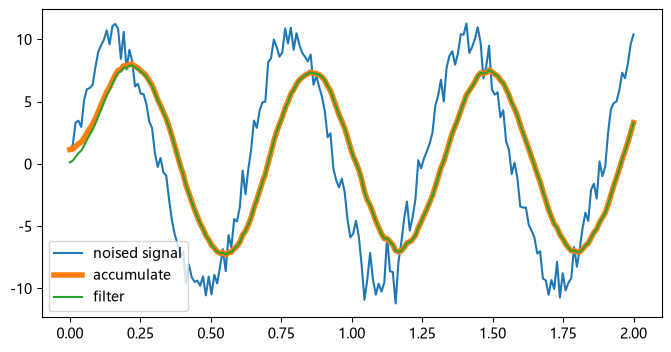

In [41]:
from matplotlib import pyplot as plt
from scipy import signal


@nb.vectorize([nb.float64(nb.float64, nb.float64)])
def weighted_add(x, y):
    return 0.9 * x + 0.1 * y


t = np.linspace(0, 2, 200)
x = np.random.randn(len(t)) + np.sin(10 * t) * 10
plt.figure(figsize=(8, 4))
plt.plot(t, x, label="noised signal")
plt.plot(t, weighted_add.accumulate(x), lw=4, label="accumulate")
plt.plot(t, signal.lfilter([0.1], [1, -0.9], x), label="filter")
plt.legend();

## 做模板(stencil)核函数

模板是“用周围固定形状的值来更新数组元素”的计算：用 Numba 的 `@stencil` 只要写核函数，外面遍历输入的循环由 Numba 生成，代码变短，再配合 `jit` 的并行指定就更快。

下面的代码是计算二维数组周围平均值的核函数：`mean_kernel()` 取当前元素 `a[0, 0]` 与右、下、左、上 4 个值的合计，再乘以 0.2。

* `a[0, 1]`：右
* `a[1, 0]`：下
* `a[0, -1]`：左
* `a[-1, 0]`：上

范围之外的元素当作 0 处理。

In [42]:
from numba import stencil


@stencil
def mean_kernel(a):
    return 0.2 * (a[0, 1] + a[1, 0] + a[0, -1] + a[-1, 0] + a[0, 0])


arr = np.random.randint(0, 10, size=(5, 5))
arr2 = mean_kernel(arr)
%C arr;arr2

       arr                     arr2           
-----------------  ---------------------------
[[2, 1, 3, 9, 4],  [[0. , 0. , 0. , 0. , 0. ],
 [0, 1, 6, 7, 3],   [0. , 2.4, 3.6, 5.8, 0. ],
 [9, 4, 1, 4, 1],   [0. , 3. , 4.6, 4. , 0. ],
 [1, 0, 8, 7, 7],   [0. , 4.2, 4. , 7. , 0. ],
 [3, 8, 4, 9, 0]]   [0. , 0. , 0. , 0. , 0. ]]


`@stencil` 返回的是 `StencilFunc`，每次调用都要编译，它不记结果，直接调用因此很慢。

本书给 `StencilFunc` 加了 `create()`，让它返回编译好的函数，调用那个就快了。

:::{seealso}
https://github.com/numba/numba/issues/6706

这是关于 `StencilFunc` 没有缓存这个问题的报告。
:::

In [43]:
import helper.numba  # 给 StencilFunc 加上 create() 方法

### 水波的模拟

用 `stencil` 把水波的模拟提速：下一步的值由当前值(`u[1]`)与前一步的值(`u[2]`)算出来，中心的值得用周围 4 个的平均与当前值的差来更新。

参考：[2D Wave Equation Simulation](https://beltoforion.de/en/recreational_mathematics/2d-wave-equation.php)

写成循环就是下面这样，其中 `u[0, c, r]` 是下一步的值、`u[1, c, r]` 是当前的值、`u[2, c, r]` 是前一步的值。

```python
for c in range(1, dimx-1):
    for r in range(1, dimy-1):
        u[0, c, r]  = 0.25 * (u[1, c-1, r] + u[1, c+1, r] + u[1, c, r-1] + u[1, c, r+1] - 4*u[1, c, r])
        u[0, c, r] += 2 * u[1, c, r] - u[2, c, r]
```

下面的代码把这个计算写成 `@stencil` 的核函数，参数有 3 个。

* `u`：当前状态的二维数组
* `u2`：前一步状态的二维数组
* `dump`：衰减的系数

`r` 由上下左右 4 点与当前点算出，最后乘上 `dump`，让波一点点减弱。

In [44]:
@stencil
def kernel(u, u2, dump):
    r = 0.25 * (u[-1, 0] + u[1, 0] + u[0, -1] + u[0, 1] - 4 * u[0, 0])
    r += 2 * u[0, 0] - u2[0, 0]
    return r * dump

用假的数组编译核函数，把结果放进 `f`。

In [45]:
u = np.zeros((3, 3))
u2 = np.zeros((3, 3))
f = kernel.create(u, u2, 0.1)

在 100×100 的数组上计算水波，每 20 帧画一张。

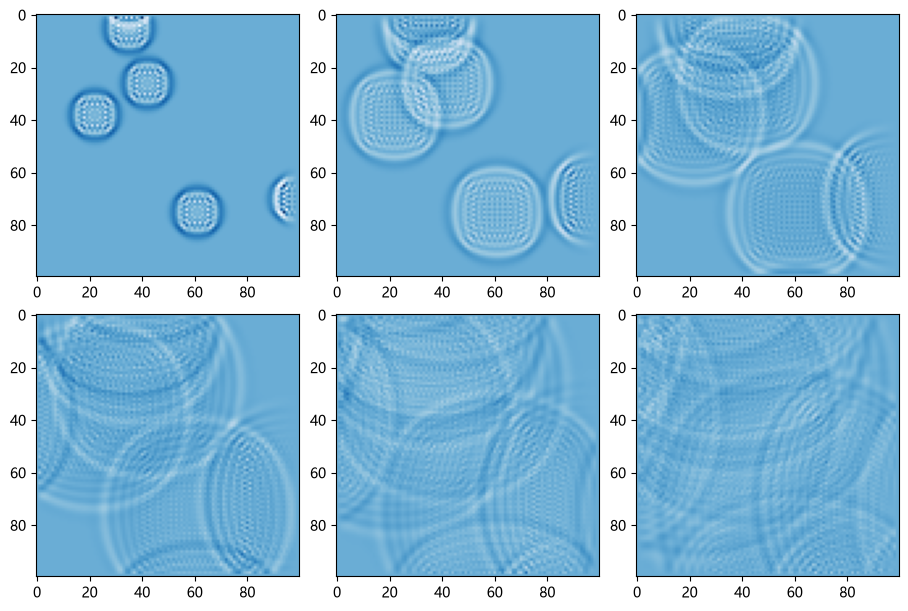

In [46]:
h, w = 100, 100
u = np.zeros((h, w))
n = 5
u[np.random.randint(0, h - 1, n), np.random.randint(0, w - 1, n)] = 120
u2 = np.zeros((h, w))

fig, axes = plt.subplots(2, 3, figsize=(9, 6), layout="constrained")

for ax in axes.ravel():
    for i in range(20):
        u_next = f.entry_point(u, u2, 0.99)
        u, u2 = u_next, u
    ax.imshow(u, cmap="Blues", vmin=-20, vmax=20)

最后用 panel 做成动画。

In [47]:
import cv2
from random import randint
from matplotlib.cm import Blues
from matplotlib.colors import Normalize
from IPython.display import display
import panel as pn

pn.extension()

下面 `WaterSim` 计算水波并当场显示结果。

* `__init__`：在中央放一个波来初始化，`self.u` 放当前状态、`self.u2` 放前一步的状态。
* `get_png`：把 `self.u` 变成颜色，做成 PNG 返回。
* `update`：前进 1 步，偶尔加上波，再用核函数算下一步的状态。
* `show`：把当前状态显示成图像。
* `run`：定期调用 `update`，按指定的秒数运行。

:::{warning}
这个动画是用 Python 计算的，在网页上不会动。
:::

PNG(bytes)
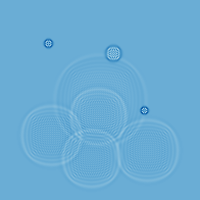

In [48]:
class WaterSim:
    def __init__(self, h, w, dump=0.99):
        self.h, self.w = h, w
        self.dump = dump
        u = np.zeros((h, w))
        u[h // 2, w // 2] = 120  # 作为初始状态在中央放一个波
        u2 = np.zeros((h, w))
        self.u = u
        self.u2 = u2
        self.norm = Normalize(vmin=-40, vmax=40, clip=True)  # 正規化
        self.cmap = Blues  # 色图
        self.image = pn.pane.PNG(self.get_png())  # 当作 PNG 图像显示
        for i in range(100):
            self.update()

    def get_png(self):
        arr2 = self.cmap(self.norm(self.u), bytes=True)[
            :, :, 2::-1
        ]  # 应用色图
        flag, img = cv2.imencode(".png", arr2)  # PNG 编码
        png = img.tobytes()  # 转换成字节数据
        return png

    def update(self):
        h, w = self.h, self.w
        if randint(0, 10) == 0:  # 随机加一个初始值
            self.u[randint(h // 5, h - h // 5), randint(w // 5, w - w // 5)] = 120

        u_next = f.entry_point(
            self.u, self.u2, self.dump
        )  # 用模板核函数计算下一步的状态
        self.u, self.u2 = u_next, self.u  # 更新当前的状态
        self.image.object = self.get_png()  # 更新图像

    def show(self):
        display(self.image)  # 显示图像

    def run(self, seconds=5):
        self.cb = pn.state.add_periodic_callback(
            self.update, 20, timeout=seconds * 1000
        )  # 定期执行 `update` 方法


sim = WaterSim(200, 200, dump=0.99)  # 做出 200x200 的模拟
sim.show()  # 显示模拟
sim.run(seconds=10)  # 运行 10 秒的模拟

In [49]:
sim.run(seconds=10)  # 再模拟接下来的 10 秒。

## 小结

* Numba 用 LLVM 把 Python 的函数变成机器码，用 `@njit` 保证不使用 Python 的对象。
* 类型用 `numba.types` 的类型对象来写，用 `typeof()` 可以查；签名也可以用字符串写。
* 数组写成 `float64[:, ::1]` 这样，指定连续之后更快。
* 局域变量的类型由推断得出，用 `inspect_types()` 与 `get_local_variables()` 确认。
* 用带类型的 `List` 与 `Dict`，元素大小一致，因此更快。
* 把整个表达式做成一个 ufunc，按广播的方式有时会更慢，要看形状挑写法。
* 用 `vectorize` 做 ufunc、用 `stencil` 写核函数；`stencil` 用 `create()` 取编译好的函数。